# Conditional operations: 
1. Fast reset
2. T-gate teleportation
3. Quantum teleportation
4. Repetition code 

Four feed-forward circuits written with the conditional API (`gates.Switch`,
`gates.IfElse`) of `CQT-qibo`'s `eo-switch-native-execution` branch.

In [1]:
# Imports
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent.parent / "CQT-qibo" / "src"))  # checked-out CQT-qibo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qibo
from qibo import Circuit, gates

qibo.set_backend("numpy")

[Qibo 0.3.7|INFO|2026-10-28 03:03:49]: Using numpy backend on /CPU:0


In [2]:
# SSH Helper
import re
import shlex
import subprocess
import time

SSH_HOST = "cqt-paul-server-nqch-deploy"  # existing ~/.ssh/config entry
REMOTE_DIR = "/mnt/home/nqch-deploy/test_qm_run"
REMOTE_PYTHON = "/mnt/scratch/nqch-deploy/eo-switch-native-execution-venv/bin/python"
REMOTE_SCRIPT = f"{REMOTE_DIR}/4_fast_reset.py"
TERMINAL_STATES = {
    "COMPLETED", "FAILED", "CANCELLED", "TIMEOUT", "OUT_OF_MEMORY",
    "NODE_FAIL", "BOOT_FAIL", "DEADLINE", "PREEMPTED", "REVOKED",
}


def _ssh(command: str) -> str:
    completed = subprocess.run(
        ["ssh", "-o", "BatchMode=yes", "-o", "ConnectTimeout=10", SSH_HOST, command],
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
        timeout=45,
    )
    if completed.returncode:
        raise RuntimeError(f"SSH command failed: {completed.stderr.strip()}")
    return completed.stdout


def _slurm_state(job_id: str) -> str:
    rows = _ssh(f"sacct -X -n -P -j {job_id} --format=JobIDRaw,State")
    for row in rows.splitlines():
        fields = row.split("|", 1)
        if len(fields) == 2 and fields[0].strip() == job_id:
            return fields[1].strip().split()[0].rstrip("+")
    queued = _ssh(f"squeue -h -j {job_id} -o %T").strip()
    return queued.splitlines()[0] if queued else "UNKNOWN"

## Fast reset

A single-round active reset: measure a qubit mid-circuit and apply `X` only if
the outcome is 1, leaving it in $|0\rangle$ ideally. Preparing $|+\rangle$
first exercises both feedback outcomes; the second measurement checks the
reset. Actual feedback speed and reset fidelity must be measured on hardware.

In [3]:
c = Circuit(1)
c.add(gates.H(0))  # prepare |+> so both feedback outcomes occur

before_reset = c.add(gates.M(0, collapse=True, register_name="before_reset"))

c.add(gates.IfElse(
    before_reset.is_one(), 
    then_do=gates.X(0)))
before_reset2 = c.add(gates.M(0, collapse=True, register_name="before_reset2"))
c.add(gates.IfElse(
    before_reset2.is_one(), 
    then_do=gates.X(0)))
c.add(gates.M(0, register_name="after_reset"))

c.draw()
result = c(nshots=1000)
print("Before reset:", before_reset.frequencies())
print("Before reset2:", before_reset2.frequencies())
print("After reset:", result.frequencies())  # ideally all 0


0: ─H─M─if[─X─][─]─M─if[─X─][─]─M─
Before reset: Counter({'0': 502, '1': 498})
Before reset2: Counter({'0': 1000})
After reset: Counter({'0': 1000})


<details>
<summary>Hardware version Fast Reset</summary>

```python
# Hardware version Fast reset
"""Run the notebook's one-qubit fast reset on sinq20 through QASM 3 and QM.

Run only inside a user-submitted Slurm job. Logical qubit 0 is pinned to
the physical qubit named by ``PHYSICAL_QUBIT``.
The mid-circuit measurement is saved as ``before_reset``; a conditional X
returns the qubit to |0> when that measurement is one; ``after_reset`` checks
the result. An optional offline QUA preflight uses the QM backend's own
translator to preview whether the measurement-controlled reset survives into
the QUA program before hardware access. The backend compiles again when run()
submits the 1000-shot circuit.
"""


import json
import os
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
PHYSICAL_QUBIT = "q15"
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Set to False to skip the optional QUA check.
EXPECTED_REGISTERS = [("before_reset", 1), ("after_reset", 1)]


def build_fast_reset() -> Circuit:
    """Measure |+>, flip a measured one to zero, then measure again."""
    circuit = Circuit(1)
    circuit.add(gates.H(0))
    before_reset = circuit.add(
        gates.M(0, collapse=True, register_name="before_reset")
    )
    circuit.add(gates.IfElse(before_reset.is_one(), then_do=gates.X(0)))
    circuit.add(gates.M(0, register_name="after_reset"))
    return circuit


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert the fast-reset circuit through QASM 3 and verify its control flow."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 1:
        raise RuntimeError("Expected exactly one logical qubit")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the reset measurement registers")
    if sum(isinstance(item.operation, IfElseOp) for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import did not preserve exactly one IfElse")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 2:
        raise RuntimeError("Expected one feedback and one final measurement")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros from working Paul script."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def transpilation(converted_circuit: QuantumCircuit, qm_backend) -> tuple[QuantumCircuit, int]:
    """Place the logical qubit and translate gates for the QM backend target."""
    # First pass: explicitly place logical qubit 0 on PHYSICAL_QUBIT.
    physical_index = qm_backend.qubit_dict[PHYSICAL_QUBIT]
    layout = Layout.from_intlist([physical_index], converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    actual = placed.layout.initial_layout[converted_circuit.qubits[0]]
    if actual != physical_index:
        raise RuntimeError(f"Logical qubit 0 was placed at {actual}, not {physical_index}")

    # Second pass: translate H to QM target gates while retaining IfElse.
    native = transpile(placed, backend=qm_backend, optimization_level=0)
    if sum(isinstance(item.operation, IfElseOp) for item in native.data) != 1:
        raise RuntimeError("QM target translation did not preserve IfElse")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != {physical_index}:
        raise RuntimeError(
            f"QM target translation moved an operation off {PHYSICAL_QUBIT}"
        )
    return native, physical_index


def run_qua_preflight(qm_backend, native) -> None:
    """Check the generated QUA offline; run() compiles again for submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if "with if_(" not in qua_script or "with if_(False)" in qua_script:
        raise RuntimeError("Unsafe or missing measurement-dependent QUA branch")
    if set(compilation.outputs.table) != {"before_reset", "after_reset"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA branch lines:", flush=True)
    for line in qua_script.splitlines():
        if "with if_(" in line or "with else_(" in line:
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Label the measured reset outcomes and report the final-zero total."""
    # Qiskit displays classical registers in reverse declaration order:
    # after_reset first, before_reset second. The QM provider may omit spaces.
    print("Hardware counts:", flush=True)
    reset_to_zero = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 2 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected after/before reset bit string: {key!r}")
        after_reset, before_reset = bits
        print(
            f"  before_reset={before_reset}  after_reset={after_reset}  shots={count}",
            flush=True,
        )
        if after_reset == "0":
            reset_to_zero += count
    print(f"Final zero outcomes: {reset_to_zero}/{shots}", flush=True)


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    # 1. Transform Qibo circuit to OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_fast_reset())

    # 2. Load from Arthur's provider Qiskit-Backend
    qm_backend = load_qm_backend()

    # 3. Transpilation: 
    # 1) Place the logical qubit(s) into physical ones
    # 2) Translate the circuit to QM native gates.
    native, physical_index = transpilation(converted_circuit, qm_backend)
    print(f"Placement: logical 0 -> {PHYSICAL_QUBIT} ({physical_index})", flush=True)
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optional QUA compilation to check qm_backend.run() will compile correctly.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. Job submission: this submits to QM only when the user submits the enclosing Slurm job.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)

    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Print out results
    report_results(counts, SHOTS)

if __name__ == "__main__":
    main()
```
</details>

### Execute Fast reset on Nqch 

In [4]:
# Fast reset execution functions
def _parse_fast_reset_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*before_reset=([01])\s+before_reset2=([01])\s+after_reset=([01])\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None
    joint_counts = {}
    for before, before2, after, count in matches:
        label = f"{before}->{before2}->{after}"  # before_reset -> before_reset2 -> after_reset
        joint_counts[label] = joint_counts.get(label, 0) + int(count)
    before_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[0] == bit)
        for bit in "01"
    }
    before2_counts = {
        bit: sum(n for label, n in joint_counts.items() if label.split("->")[1] == bit)
        for bit in "01"
    }
    after_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[-1] == bit)
        for bit in "01"
    }
    return {
        "joint_counts": joint_counts,
        "before_reset_counts": before_counts,
        "before_reset2_counts": before2_counts,
        "after_reset_counts": after_counts,
        "first_reset_zero_count": before2_counts["0"],
        "final_zero_count": after_counts["0"],
    }


def submit_fast_reset_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one fast-reset Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(REMOTE_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=fast_reset "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_fast_reset_measurements(raw_stdout),
    }


Run the next cell only when you want to submit the fast-reset job. It waits for that job and stores its logs and counts in `fast_reset_job`. Interrupting the notebook wait does not cancel the Slurm job.

In [ ]:
# Submit slurm job
fast_reset_job = submit_fast_reset_job()
fast_reset_job["measurement_results"]

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 66185
Job 66185: PENDING
Job 66185: COMPLETED


{'joint_counts': {'0->0->0': 522,
  '1->0->0': 416,
  '0->1->0': 2,
  '1->1->0': 52,
  '0->0->1': 2,
  '1->0->1': 2,
  '1->1->1': 4},
 'before_reset_counts': {'0': 526, '1': 474},
 'before_reset2_counts': {'0': 942, '1': 58},
 'after_reset_counts': {'0': 992, '1': 8},
 'first_reset_zero_count': 942,
 'final_zero_count': 992}

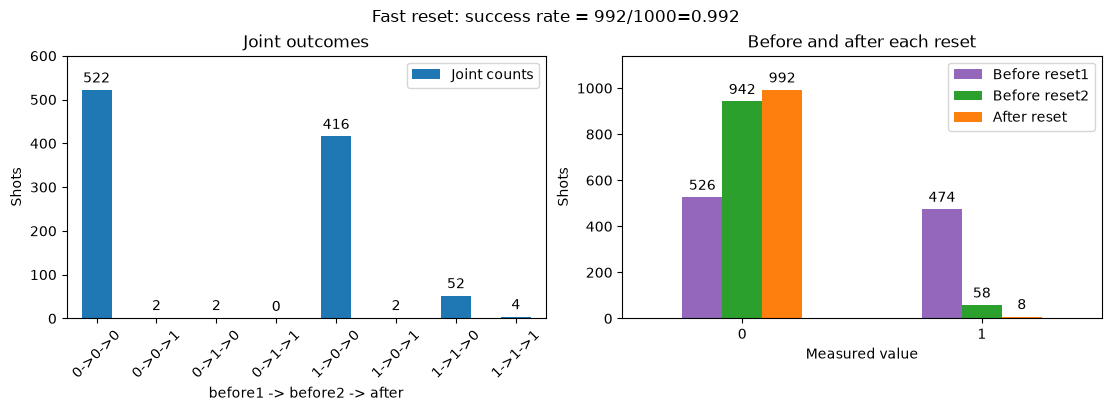

In [6]:
# Plotting
results = fast_reset_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect fast_reset_job['raw_logs'].")

transitions = ["->".join(f"{value:03b}") for value in range(8)]  # before_reset1 -> before_reset2 -> after_reset
joint_counts = pd.DataFrame(
    {"Joint counts": [results["joint_counts"].get(label, 0) for label in transitions]},
    index=transitions,
)
before_after_counts = pd.DataFrame(
    {
        "Before reset1": [results["before_reset_counts"].get(bit, 0) for bit in ("0", "1")],
        "Before reset2": [results["before_reset2_counts"].get(bit, 0) for bit in ("0", "1")],
        "After reset": [results["after_reset_counts"].get(bit, 0) for bit in ("0", "1")],
    },
    index=["0", "1"],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
shots = int(joint_counts["Joint counts"].sum())
succ_rate = results['final_zero_count']/shots
fig.suptitle(f"Fast reset: success rate = {results['final_zero_count']}/{shots}={succ_rate}")
joint_counts.plot.bar(ax=axes[0], color="tab:blue", rot=45, legend=True)
before_after_counts.plot.bar(
    ax=axes[1], color=["tab:purple", "tab:green", "tab:orange"], rot=0, legend=True
)
axes[0].set(title="Joint outcomes", xlabel="before1 -> before2 -> after", ylabel="Shots")
axes[1].set(title="Before and after each reset", xlabel="Measured value", ylabel="Shots")
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.15)
plt.show()

**How to read the fast-reset plots**

- **Left (blue):** Each bar counts shots with one *before → after* outcome on the same qubit. For example, `1→0` means the first measurement was 1 and the reset left the final measurement at 0. Both `0→0` and `1→0` end at the desired 0.
- **Right (purple and orange):** At each measured value (0 or 1), purple counts outcomes **before** reset and orange counts outcomes **after** reset. A taller orange bar at 0 means more shots ended at 0. The title reports that final-zero count divided by all shots.

## T-gate teleportation

Qubit 0 holds the input $|+\rangle$ and qubit 1 the magic state $T|+\rangle$. After the
CNOT, measuring qubit 1 leaves $T|+\rangle$ on qubit 0 for outcome 0 and $T^\dagger|+\rangle$
for outcome 1, which the conditional $S$ corrects ($S\,T^\dagger = T$). Measuring
$T|+\rangle$ in the X basis gives $P(1) = \sin^2(\pi/8) \approx 0.146$.

In [7]:
c = Circuit(3)

# Prepare state |+⟩ for q_0
c.add(gates.H(0)) 

# Prepare state T|+⟩ for q_1
c.add(gates.H(1)) 
c.add(gates.T(1)) # here T gate to add a 45º phase

# CNOT Links the two qubits so the T phase is part of their shared state.
c.add(gates.CNOT(0, 1)) 

# Then we measure qubit 1 because:
# if q_1= 0 then q_0 will be in T|+⟩ state so no need to do anything. We've teleported the phase.
# if q_1 =1 then q_0 will be in Tdagga|+⟩ state (the phase is in the |0⟩ not the |1⟩)
# in that case we need to apply an S gate to correct and leave q_0 in T|+⟩
m1 = c.add(gates.M(1, collapse=True))
c.add(gates.IfElse(m1.is_one(), then_do=gates.S(0)))

# Measure qubit_0 to get how well we teleported the T-gate
# measurement is H+M coz quantum measurements can only see probabilities (amplitudes), not phases.
c.add(gates.H(0))
m0 = c.add(gates.M(0, register_name="teleported"))

# # Prepare state T|+⟩ for q_2 & measure to have reference to compare our teleportation against
c.add(gates.H(2))
c.add(gates.T(2))
c.add(gates.H(2))
m2 = c.add(gates.M(2, register_name="local"))

c.draw()
nshots = 10000
c(nshots=nshots)
p1_teleported = m0.frequencies()["1"] / nshots
p1_local = m2.frequencies()["1"] / nshots
print(f"P(1) teleported = {p1_teleported:.3f}, expected sin^2(pi/8) = {np.sin(np.pi / 8) ** 2:.3f}")
print(f"P(1) local = {p1_local:.3f}, expected sin^2(pi/8) = {np.sin(np.pi / 8) ** 2:.3f}")

0: ─H───o───if[─S─][─]─H─M─
1: ─H─T─X─M────────────────
2: ───────H─T───H─M────────
P(1) teleported = 0.146, expected sin^2(pi/8) = 0.146
P(1) local = 0.137, expected sin^2(pi/8) = 0.146


<details>
<summary>Hardware version Teleportation</summary>

```python
"""Run the notebook's T-gate teleportation circuit on sinq20 through QASM 3 and QM.

Run only inside a user-submitted Slurm job. Logical qubits 0 and 1 are pinned
respectively to the physical qubits named in ``PHYSICAL_QUBITS``. The first
measurement controls an S correction on qubit 0; the final X-basis measurement
of qubit 0 should give P(1) near sin^2(pi/8) on ideal hardware. An optional
offline QUA preflight checks that the measurement-dependent branch survives
translation before the backend opens a hardware session. The backend compiles
again when run() submits the 1000-shot circuit.
"""

import json
import math
import os
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
PHYSICAL_QUBITS = ("q15", "q19")
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Set to False to skip the optional QUA check.
EXPECTED_REGISTERS = [("feedback", 1), ("result", 1)]


def build_teleportation() -> Circuit:
    """Prepare a magic state, teleport T onto qubit 0, and measure in X."""
    circuit = Circuit(2)
    circuit.add(gates.H(0))
    circuit.add(gates.H(1))
    circuit.add(gates.T(1))
    circuit.add(gates.CNOT(0, 1))
    feedback = circuit.add(gates.M(1, collapse=True, register_name="feedback"))
    circuit.add(gates.IfElse(feedback.is_one(), then_do=gates.S(0)))
    circuit.add(gates.H(0))
    circuit.add(gates.M(0, register_name="result"))
    return circuit


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert through OpenQASM 3 and verify the teleportation control flow."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 2:
        raise RuntimeError("Expected exactly two logical qubits")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the teleportation registers")
    if sum(isinstance(item.operation, IfElseOp) for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import did not preserve exactly one IfElse")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 2:
        raise RuntimeError("Expected one feedback and one final measurement")
    if sum(item.operation.name == "cx" for item in qiskit_circuit.data) != 1:
        raise RuntimeError("QASM import changed the teleportation CNOT")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros as fast reset."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def transpilation(converted_circuit: QuantumCircuit, qm_backend) -> tuple[QuantumCircuit, list[int]]:
    """Place both logical qubits and translate gates for the QM target."""
    physical_indices = [qm_backend.qubit_dict[name] for name in PHYSICAL_QUBITS]
    layout = Layout.from_intlist(physical_indices, converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    for logical_index, physical_index in enumerate(physical_indices):
        actual = placed.layout.initial_layout[converted_circuit.qubits[logical_index]]
        if actual != physical_index:
            raise RuntimeError(
                f"Logical qubit {logical_index} was placed at {actual}, "
                f"not {physical_index}"
            )

    # Translate H, T, S, and CNOT to gates supported by the QM target.
    native = transpile(placed, backend=qm_backend, optimization_level=0)
    if sum(isinstance(item.operation, IfElseOp) for item in native.data) != 1:
        raise RuntimeError("QM target translation did not preserve IfElse")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != set(physical_indices):
        raise RuntimeError("QM target translation moved an operation off q15/q19")
    if native.count_ops().get("cz", 0) < 1:
        raise RuntimeError("QM target translation did not map CNOT to a CZ")
    return native, physical_indices


def run_qua_preflight(qm_backend, native: QuantumCircuit) -> None:
    """Check the generated QUA offline; run() compiles again for submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if "with if_(" not in qua_script or "with if_(False)" in qua_script:
        raise RuntimeError("Unsafe or missing measurement-dependent QUA branch")
    if set(compilation.outputs.table) != {"feedback", "result"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA branch lines:", flush=True)
    for line in qua_script.splitlines():
        if "with if_(" in line or "with else_(" in line:
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Label feedback/final outcomes and report the final-one frequency."""
    # Qiskit displays registers in reverse declaration order: result, feedback.
    # The QM provider may omit spaces between the two register values.
    print("Hardware counts:", flush=True)
    final_one_count = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 2 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected result/feedback bit string: {key!r}")
        result_bit, feedback_bit = bits
        print(
            f"  feedback={feedback_bit}  result={result_bit}  shots={count}",
            flush=True,
        )
        if result_bit == "1":
            final_one_count += count
    print(f"Final one outcomes: {final_one_count}/{shots}", flush=True)
    print(
        f"P(1) = {final_one_count / shots:.3f}; "
        f"ideal sin^2(pi/8) = {math.sin(math.pi / 8) ** 2:.3f}",
        flush=True,
    )


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    # 1. Transform the Qibo circuit through OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_teleportation())

    # 2. Load Arthur's provider Qiskit backend using the sinq20 configuration.
    qm_backend = load_qm_backend()

    # 3. Place both qubits and translate the circuit to QM target gates.
    native, physical_indices = transpilation(converted_circuit, qm_backend)
    print(
        f"Placement: logical 0 -> {PHYSICAL_QUBITS[0]} ({physical_indices[0]}), "
        f"logical 1 -> {PHYSICAL_QUBITS[1]} ({physical_indices[1]})",
        flush=True,
    )
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optionally check QUA compilation before opening a hardware session.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. The user submits the Slurm job; this call submits to QM once inside it.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)
    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Report measured results.
    report_results(counts, SHOTS)


if __name__ == "__main__":
    main()


```

</details>

### Execute Teleportation on Nqch 

In [8]:
# Teleportation execution functions
TELEPORTATION_SCRIPT = f"{REMOTE_DIR}/5_teleportation.py"


def _parse_teleportation_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*feedback=([01])\s+teleported=([01])\s+local=([01])\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None

    joint_counts = {}
    local_counts = {"0": 0, "1": 0}
    for feedback, teleported, local, count in matches:
        label = f"{feedback}->{teleported}"  # feedback measurement -> teleported measurement
        joint_counts[label] = joint_counts.get(label, 0) + int(count)
        local_counts[local] += int(count)  # local HTH reference, independent of feedback
    feedback_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[0] == bit)
        for bit in "01"
    }
    teleported_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[-1] == bit)
        for bit in "01"
    }
    shots = sum(joint_counts.values())
    if shots == 0:
        raise RuntimeError("Teleportation log contains no measurement shots")
    teleported_one_count = teleported_counts["1"]
    local_one_count = local_counts["1"]

    for name, one_count in (("Teleported", teleported_one_count), ("Local", local_one_count)):
        summary = re.search(
            rf"^{name} one outcomes:\s*(\d+)/(\d+)\s*$",
            raw_stdout,
            flags=re.MULTILINE,
        )
        if summary and (int(summary.group(1)), int(summary.group(2))) != (one_count, shots):
            raise RuntimeError(f"{name} summary disagrees with the hardware counts")

    return {
        "joint_counts": joint_counts,
        "feedback_counts": feedback_counts,
        "teleported_counts": teleported_counts,
        "local_counts": local_counts,
        "teleported_one_count": teleported_one_count,
        "local_one_count": local_one_count,
        "shots": shots,
        "p1_teleported": teleported_one_count / shots,
        "p1_local": local_one_count / shots,
    }


def submit_teleportation_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one teleportation Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(TELEPORTATION_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=teleportation "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_teleportation_measurements(raw_stdout),
    }


Run the next cell only when you want to submit the teleportation job. It waits for that job and stores its logs and counts in `teleportation_job`. Interrupting the notebook wait does not cancel the Slurm job.

In [ ]:
# Submit slurm job
teleportation_job = submit_teleportation_job()
print("Teleportation measurement results:", teleportation_job["measurement_results"])

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 66186
Job 66186: PENDING
Job 66186: COMPLETED
Teleportation measurement results: {'joint_counts': {'0->0': 4193, '1->0': 4186, '0->1': 787, '1->1': 834}, 'feedback_counts': {'0': 4980, '1': 5020}, 'teleported_counts': {'0': 8379, '1': 1621}, 'local_counts': {'0': 8556, '1': 1444}, 'teleported_one_count': 1621, 'local_one_count': 1444, 'shots': 10000, 'p1_teleported': 0.1621, 'p1_local': 0.1444}


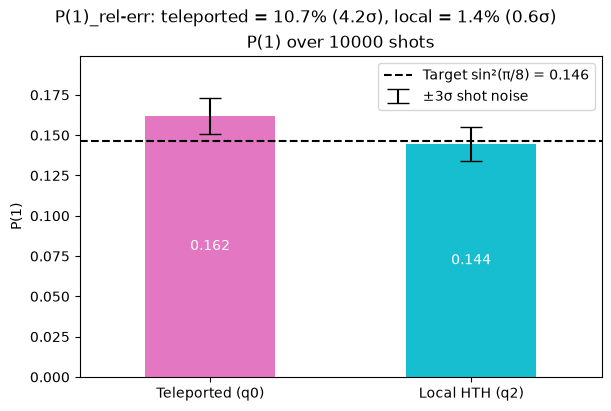

In [23]:
# Teleportation plots
results = teleportation_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect teleportation_job['raw_logs'].")

p1_values = pd.Series(
    {
        "Teleported (q0)": results["p1_teleported"],
        "Local HTH (q2)": results["p1_local"],
    }
)
theoretical_p1 = np.sin(np.pi / 8) ** 2  # Approximately 0.146
relative_error_percent = (p1_values - theoretical_p1).abs() / theoretical_p1 * 100
# Binomial shot-noise standard error of each P(1) estimate.
p1_sigma = np.sqrt(p1_values * (1 - p1_values) / results["shots"])
deviation_sigma = (p1_values - theoretical_p1).abs() / p1_sigma

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
fig.suptitle(
    f"P(1)_rel-err: teleported = {relative_error_percent['Teleported (q0)']:.1f}% "
    f"({deviation_sigma['Teleported (q0)']:.1f}σ), "
    f"local = {relative_error_percent['Local HTH (q2)']:.1f}% "
    f"({deviation_sigma['Local HTH (q2)']:.1f}σ)"
)
p1_values.plot.bar(ax=ax, color=["tab:pink", "tab:cyan"], rot=0)
ax.errorbar(
    range(len(p1_values)), p1_values, yerr=3 * p1_sigma,
    fmt="none", ecolor="black", capsize=8, label="±3σ shot noise",
)
ax.axhline(
    theoretical_p1, color="black", linestyle="--",
    label=f"Target sin²(π/8) = {theoretical_p1:.3f}",
)
ax.set(title=f"P(1) over {results['shots']} shots", ylabel="P(1)")
ax.bar_label(ax.containers[0], fmt="%.3f", label_type="center", color="white")
ax.legend()
ax.margins(y=0.15)
plt.show()

**How to read the T-gate teleportation plot**<br>
The pink bar shows how often the teleported qubit measured 1;<br>
The cyan bar shows the same measurement after applying T directly to a separate qubit.<br>
The dashed line is the ideal value, (P(1)= sin^2(pi/8) approx= 0.146).<br> 
The black error bars show the range expected from finite-shot variation.<br>
The title reports the relative errors in percentage form.<br>
P(1) is a measurement probability, not a teleportation success rate, just a proxy.

## Quantum teleportation

Three-qubit teleportation of the state $|-\rangle$. Qubit 0 holds the input $|-\rangle$, prepared with $X$ then $H$; qubits 1 and 2 are entangled with Hadamards and a CZ. A CZ-based Bell measurement of qubits 0 and 1 gives `feedback_z` (qubit 0) and `feedback_x` (qubit 1), which conditionally apply $Z$ and $X$ to qubit 2. A final $H$ maps the teleported $|-\rangle$ to $|1\rangle$, so measuring `result` = 1 counts as a successful teleportation.

On hardware, logical qubits 0, 1, 2 are **q19, q15, q10**; the two CZ gates use the q15–q10 and q19–q15 couplings.

In [11]:
# The key here in this teleportation is that, because of the entanglement,
# collapsing qubits q_0 and q_1 leaves qubit q_2 holding the exact original
# |-⟩ state (plus or minus an X or Z flip, which we correct).

c = Circuit(3)

# Prepare state |-⟩ for q_0, this is the state to teleport
c.add(gates.X(0))
c.add(gates.H(0))  

# Prepare Bell state of q_1 & q_2 so they are maximally entangled
# CZ gate achieves so by flipping the sign of |11>
c.add(gates.H(2))
c.add(gates.H(1))
c.add(gates.CZ(1, 2))  

# Entangle qubits q_0 & q_1 so their states are correlated
c.add(gates.CZ(0, 1))

# Apply Hadamard gates to qubits q_0 and q_1 to rotate them back to the Z-axis measurement basis
c.add(gates.H(1))
c.add(gates.H(0))

# Measure qubits q_1 and q_0 to obtain classical feedback bits
feedback_x = c.add(gates.M(1, collapse=True, register_name="feedback_x"))
feedback_z = c.add(gates.M(0, collapse=True, register_name="feedback_z"))

# Conditionally correct qubit 2 based on the measurement feedback:
c.add(gates.IfElse(feedback_x.is_one(), then_do=gates.X(2)))
c.add(gates.IfElse(feedback_z.is_one(), then_do=gates.Z(2)))

# Apply a final Hadamard to qubit 2 to map the teleported |-⟩ state to |1⟩ for measurement
c.add(gates.H(2))  
c.add(gates.M(2, register_name="result"))

c.draw()
result = c(nshots=1000)
print("Feedback X:", feedback_x.frequencies())
print("Feedback Z:", feedback_z.frequencies())
print("Result:", result.frequencies())  # ideally all 1

0: ─X─H───o─H─M───────────────────────────
1: ─H───o─Z─H─M───────────────────────────
2: ─H───Z───────if[─X─][─]─if[─Z─][─]─H─M─
Feedback X: Counter({'1': 511, '0': 489})
Feedback Z: Counter({'0': 504, '1': 496})
Result: Counter({'1': 1000})


<details>
<summary>Hardware version Quantum Teleportation</summary>

```python
"""Run the notebook's three-qubit quantum teleportation on sinq20 through QASM 3 and QM.

Run only inside a user-submitted Slurm job. Logical qubits 0, 1, and 2 are
pinned respectively to the physical qubits named in ``PHYSICAL_QUBITS``.
Qubit 0 holds the input state |->, and qubits 1 and 2 share a Bell pair made
with CZ. The Bell measurement of qubits 0 and 1 gives ``feedback_z`` and
``feedback_x``, which control Z and X corrections on qubit 2. A final H maps
the teleported |-> to |1>, so ``result`` = 1 marks a successful teleportation
on ideal hardware. An optional offline QUA preflight checks that both
measurement-dependent branches survive translation before the backend opens a
hardware session. The backend compiles again when run() submits the circuit.
"""

import json
import os
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
PHYSICAL_QUBITS = ("q19", "q15", "q10")
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True  # Set to False to skip the optional QUA check.
EXPECTED_REGISTERS = [("feedback_x", 1), ("feedback_z", 1), ("result", 1)]


def build_teleportation() -> Circuit:
    """Teleport |-> from qubit 0 to qubit 2, then map it to |1> and measure."""
    circuit = Circuit(3)
    circuit.add(gates.X(0))
    circuit.add(gates.H(0))

    circuit.add(gates.H(2))

    circuit.add(gates.H(1))
    circuit.add(gates.CZ(1, 2))

    circuit.add(gates.CZ(0, 1))
    circuit.add(gates.H(1))

    circuit.add(gates.H(0))
    feedback_x = circuit.add(gates.M(1, collapse=True, register_name="feedback_x"))
    feedback_z = circuit.add(gates.M(0, collapse=True, register_name="feedback_z"))

    circuit.add(gates.IfElse(feedback_x.is_one(), then_do=gates.X(2)))
    circuit.add(gates.IfElse(feedback_z.is_one(), then_do=gates.Z(2)))
    
    circuit.add(gates.H(2))
    circuit.add(gates.M(2, register_name="result"))
    return circuit


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    """Convert through OpenQASM 3 and verify the teleportation control flow."""
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 3:
        raise RuntimeError("Expected exactly three logical qubits")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the teleportation registers")
    if sum(isinstance(item.operation, IfElseOp) for item in qiskit_circuit.data) != 2:
        raise RuntimeError("QASM import did not preserve exactly two IfElse")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 3:
        raise RuntimeError("Expected two feedback and one final measurement")
    if sum(item.operation.name == "cz" for item in qiskit_circuit.data) != 2:
        raise RuntimeError("QASM import changed the two teleportation CZ gates")
    return qiskit_circuit


def load_qm_backend():
    """Use the same sinq20 QuAM state, wiring, and macros as fast reset."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def transpilation(converted_circuit: QuantumCircuit, qm_backend) -> tuple[QuantumCircuit, list[int]]:
    """Place the three logical qubits and translate gates for the QM target."""
    physical_indices = [qm_backend.qubit_dict[name] for name in PHYSICAL_QUBITS]
    layout = Layout.from_intlist(physical_indices, converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    for logical_index, physical_index in enumerate(physical_indices):
        actual = placed.layout.initial_layout[converted_circuit.qubits[logical_index]]
        if actual != physical_index:
            raise RuntimeError(
                f"Logical qubit {logical_index} was placed at {actual}, "
                f"not {physical_index}"
            )

    # Translate X, H, and Z to gates supported by the QM target.
    native = transpile(placed, backend=qm_backend, optimization_level=0)
    if sum(isinstance(item.operation, IfElseOp) for item in native.data) != 2:
        raise RuntimeError("QM target translation did not preserve both IfElse")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index
        for item in native.data for qubit in item.qubits
    }
    if active_indices != set(physical_indices):
        raise RuntimeError(
            f"QM target translation moved an operation off {'/'.join(PHYSICAL_QUBITS)}"
        )
    # Any routing SWAP would add CZ gates, so exactly two means both CZ edges exist.
    if native.count_ops().get("cz", 0) != 2:
        raise RuntimeError("QM target translation changed the two CZ gates")
    return native, physical_indices


def run_qua_preflight(qm_backend, native: QuantumCircuit) -> None:
    """Check the generated QUA offline; run() compiles again for submission."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if "with if_(" not in qua_script or "with if_(False)" in qua_script:
        raise RuntimeError("Unsafe or missing measurement-dependent QUA branch")
    if qua_script.count("with if_(") < 2:
        raise RuntimeError("Expected two measurement-dependent QUA correction branches")
    if set(compilation.outputs.table) != {"feedback_x", "feedback_z", "result"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA branch lines:", flush=True)
    for line in qua_script.splitlines():
        if "with if_(" in line or "with else_(" in line:
            print(f"  {line.strip()}", flush=True)


def report_results(counts, shots: int) -> None:
    """Label feedback/final outcomes and report the final-one (success) frequency."""
    # Qiskit displays registers in reverse declaration order: result,
    # feedback_z, feedback_x. The QM provider may omit spaces between them.
    print("Hardware counts:", flush=True)
    final_one_count = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 3 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected result/feedback bit string: {key!r}")
        result_bit, feedback_z_bit, feedback_x_bit = bits
        print(
            f"  feedback_x={feedback_x_bit}  feedback_z={feedback_z_bit}  "
            f"result={result_bit}  shots={count}",
            flush=True,
        )
        if result_bit == "1":
            final_one_count += count
    print(f"Final one outcomes: {final_one_count}/{shots}", flush=True)
    print(f"P(1) = {final_one_count / shots:.3f}; ideal = 1.000", flush=True)


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    # 1. Transform the Qibo circuit through OpenQASM 3 to Qiskit.
    converted_circuit = qibo_to_openqasm3_to_qiskit(build_teleportation())

    # 2. Load Arthur's provider Qiskit backend using the sinq20 configuration.
    qm_backend = load_qm_backend()

    # 3. Place the three qubits and translate the circuit to QM target gates.
    native, physical_indices = transpilation(converted_circuit, qm_backend)
    print(
        f"Placement: logical 0 -> {PHYSICAL_QUBITS[0]} ({physical_indices[0]}), "
        f"logical 1 -> {PHYSICAL_QUBITS[1]} ({physical_indices[1]}), "
        f"logical 2 -> {PHYSICAL_QUBITS[2]} ({physical_indices[2]})",
        flush=True,
    )
    print(f"Shots: {SHOTS}", flush=True)

    # 4. Optionally check QUA compilation before opening a hardware session.
    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # 5. The user submits the Slurm job; this call submits to QM once inside it.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)
    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")

    # 6. Report measured results.
    report_results(counts, SHOTS)


if __name__ == "__main__":
    main()
```

</details>

### Execute Quantum teleportation on Nqch

In [12]:
# Quantum teleportation execution functions
QUANTUM_TELEPORTATION_SCRIPT = f"{REMOTE_DIR}/6_quantum_teleportation.py"


def _parse_quantum_teleportation_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*feedback_x=([01])\s+feedback_z=([01])\s+result=([01])\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None

    joint_counts = {}
    for feedback_x, feedback_z, result, count in matches:
        label = f"{feedback_x}{feedback_z}->{result}"  # feedback_x, feedback_z -> final measurement
        joint_counts[label] = joint_counts.get(label, 0) + int(count)
    feedback_x_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[0] == bit)
        for bit in "01"
    }
    feedback_z_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[1] == bit)
        for bit in "01"
    }
    result_counts = {
        bit: sum(n for label, n in joint_counts.items() if label[-1] == bit)
        for bit in "01"
    }
    shots = sum(joint_counts.values())
    if shots == 0:
        raise RuntimeError("Quantum teleportation log contains no measurement shots")
    final_one_count = result_counts["1"]

    summary = re.search(
        r"^Final one outcomes:\s*(\d+)/(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if summary and (int(summary.group(1)), int(summary.group(2))) != (final_one_count, shots):
        raise RuntimeError("Quantum teleportation summary disagrees with the hardware counts")

    return {
        "joint_counts": joint_counts,
        "feedback_x_counts": feedback_x_counts,
        "feedback_z_counts": feedback_z_counts,
        "result_counts": result_counts,
        "final_one_count": final_one_count,
        "shots": shots,
        "p1": final_one_count / shots,
    }


def submit_quantum_teleportation_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one quantum-teleportation Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(QUANTUM_TELEPORTATION_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=quantum_teleportation "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_quantum_teleportation_measurements(raw_stdout),
    }

Run the next cell only after `6_quantum_teleportation.py` has been copied to the server's `REMOTE_DIR`, and only when you want to submit the quantum-teleportation job. It waits for that job and stores its logs and counts in `quantum_teleportation_job`. Interrupting the notebook wait does not cancel the Slurm job.

In [ ]:
# Submit slurm job
quantum_teleportation_job = submit_quantum_teleportation_job()
print("Quantum teleportation measurement results:", quantum_teleportation_job["measurement_results"])

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 66190
Job 66190: RUNNING
Job 66190: COMPLETED
Quantum teleportation measurement results: {'joint_counts': {'00->0': 104, '10->0': 69, '01->0': 97, '11->0': 70, '00->1': 181, '10->1': 148, '01->1': 175, '11->1': 156}, 'feedback_x_counts': {'0': 557, '1': 443}, 'feedback_z_counts': {'0': 502, '1': 498}, 'result_counts': {'0': 340, '1': 660}, 'final_one_count': 660, 'shots': 1000, 'p1': 0.66}


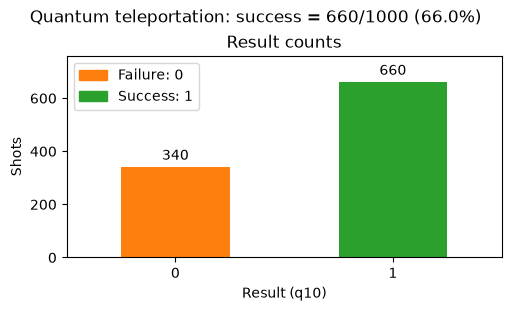

In [30]:
# Quantum teleportation plot
from matplotlib.patches import Patch

results = quantum_teleportation_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect quantum_teleportation_job['raw_logs'].")

result_labels = ["0", "1"]
result_counts = pd.Series(
    {label: results["result_counts"].get(label, 0) for label in result_labels}
)

fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)
fig.suptitle(
    f"Quantum teleportation: success = {results['final_one_count']}/{results['shots']} "
    f"({results['p1']:.1%})"
)
result_colors = ["tab:green" if label == "1" else "tab:orange" for label in result_labels]
result_counts.plot.bar(ax=ax, color=result_colors, rot=0)
ax.set(title="Result counts", xlabel="Result (q10)", ylabel="Shots")
ax.legend(handles=[
    Patch(color="tab:orange", label="Failure: 0"),
    Patch(color="tab:green", label="Success: 1"),
])
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.margins(y=0.15)
plt.show()

**How to read the quantum-teleportation plot**

Each bar counts shots whose final `result` measurement on q10 (logical qubit 2) gave 0 or 1. Ideally every shot gives 1 (green), whatever the two feedback bits were; shots at 0 (orange) are failed teleportations. The title gives the success fraction.

## Repetition code

Three data qubits encode **one logical qubit**; two ancillas read its parity checks. In a repetition code, parity checks let you detect if an error (like an unintended bit-flip) has occurred. This example prepares every data qubit in $|+\rangle$, so the parity measurement gives each of the four syndromes with equal probability, and uses `Switch` to correct each one. A syndrome is the combined result of all your parity check measurements. After correction the data should read only `000` or `111`, about half the shots each.

The circuit wires 0–4 occupy **q4, q5, q10, q15, q19**, which form a line on the chip: data q4, ancilla q5, data q10, ancilla q15, data q19. Each ancilla is coupled to both data qubits it checks (q5 to q4 and q10; q15 to q10 and q19), so no SWAP is needed. The syndrome is measured in **q5, q15** order; the final data are measured in **q4, q10, q19** order.

In [15]:
# Circuit wire -> physical qubit:
# 0 -> q4 (data 0), 1 -> q5 (ancilla 0), 2 -> q10 (data 1),
# 3 -> q15 (ancilla 1), 4 -> q19 (data 2).
data0, anc0, data1, anc1, data2 = range(5)
c = Circuit(5, wire_names=["q4", "q5", "q10", "q15", "q19"])

# Earlier version: inject an X error on the middle data state (disabled).
# c.add(gates.X(data1))

# Put every data qubit in |+> so all four syndromes occur.
c.add(gates.H(data0))
c.add(gates.H(data1))
c.add(gates.H(data2))

c.add(gates.H(anc0))
c.add(gates.H(anc1))

# Parity checks let you detect if an error (like an unintended bit-flip) has occurred.
# Parity checks on the q4-q5-q10-q15-q19 line: q5 checks q4/q10, q15 checks q10/q19.
c.add(gates.CZ(anc0, data1))
c.add(gates.CZ(anc1, data2))
c.add(gates.CZ(anc0, data0))
c.add(gates.CZ(anc1, data1))

c.add(gates.H(anc0))
c.add(gates.H(anc1))

syndrome = c.add(
    gates.M(anc0, anc1, collapse=True, register_name="syndrome")
)
c.add(
    gates.Switch(syndrome)
    .case("10", gates.X(data0))
    .case("11", gates.X(data1))
    .case("01", gates.X(data2))
    .default([])  # "00": no error
)
c.add(gates.M(data0, data1, data2, register_name="result"))

c.draw()
print(c(nshots=1000).frequencies())  # ideal result: only 000 and 111

q4 : ─H─────Z───────switch[─X─][───][───][─]─M─
q5 : ─H─o───o───H─M─|─────────|────|────|──|─|─
q10: ─H─Z─────Z───|─switch[───][─X─][───][─]─M─
q15: ─H───o───o─H─M─|─────────|────|────|──|─|─
q19: ─H───Z─────────switch[───][───][─X─][─]─M─
Counter({'000': 516, '111': 484})


**What the Correction (Switch) Does:<br>**
When the circuit measures the syndromes and uses the Switch statement to apply corrections, it forces every part of that 8-term superposition into the nearest valid codeword (`000` or `111`).<br>

Specifically:
States like 000, 001, 010, and 100 get corrected to 000.<br>
States like 111, 110, 101, and 011 get corrected to 111.

**The final state:**<br>
Because half of the 8 original superposition terms map to `000` and the other half map to `111`, the correction process transforms the initial state into a clean logical superposition:<br>
$$\frac{1}{\sqrt{2}} \big( \vert{}000\rangle + \vert{}111\rangle \big)$$

When you finally measure the three data qubits at the end, the superposition collapses. Because both terms have an amplitude of $\frac{1}{\sqrt{2}}$, squaring those amplitudes gives:<br>
$P(000) = \left\vert{}\frac{1}{\sqrt{2}}\right\vert{}^2 = \frac{1}{2}$ (50%)<br>
$P(111) = \left\vert{}\frac{1}{\sqrt{2}}\right\vert{}^2 = \frac{1}{2}$ (50%)<br>

This is why a run of 1000 shots will split evenly between 000 and 111.

<details>
<summary>Hardware version Repetition Code</summary>

```python
"""Run the notebook's five-qubit repetition code on sinq20 through QM.

Three data qubits (q4, q10, q19) encode one logical qubit. The first ancilla
(q5) checks q4/q10 and the second ancilla (q15) checks q10/q19. The five
qubits form the line q4-q5-q10-q15-q19, so all CZ gates use the q4-q5,
q5-q10, q10-q15, and q15-q19 connections and no SWAP is needed.

All three data qubits start in |+>, so the parity measurement gives each of
the four syndromes with equal probability. The Switch correction then leaves
the data in 000 or 111, which are the only ideal final outcomes.

Qibo exports the syndrome Switch as OpenQASM 3 register comparisons. The
offline QUA preflight checks that these comparisons remain dynamic before a
QM session opens. A user must submit this script as a Slurm job.
"""

import json
import os
import re
from pathlib import Path

import qiskit.qasm3
from qibo import Circuit, gates
from qibo_qm_provider import FluxTunableTransmonBackend, add_basic_macros
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.controlflow import IfElseOp
from qiskit.transpiler import Layout
from qm import generate_qua_script
from quam_config import Quam


SINQ20_ROOT = Path("/mnt/scratch/qibolab_platforms_nqch/sinq20")
SHOTS = 1000
ENABLE_QUA_PREFLIGHT = True

# Physical qubits for circuit wires 0, 1, 2, 3, 4:
# data 0, ancilla 0, data 1, ancilla 1, data 2.
PHYSICAL_QUBITS = ("q4", "q5", "q10", "q15", "q19")
REQUIRED_CZ_EDGES = ((0, 1), (1, 2), (2, 3), (3, 4))
EXPECTED_CZ_COUNT = 4  # Four parity CZs, one per line edge.
EXPECTED_REGISTERS = [("syndrome", 2), ("result", 3)]
EXPECTED_SYNDROME_CASES = (1, 3, 2)  # QASM integers for 10, 11, 01.


def build_repetition() -> Circuit:
    """Inject one X error, measure parity, correct it, and measure the data."""
    data0, anc0, data1, anc1, data2 = range(5)
    circuit = Circuit(5, wire_names=list(PHYSICAL_QUBITS))

    # Put every data qubit in |+> so all four syndromes occur.
    circuit.add(gates.H(data0))
    circuit.add(gates.H(data1))
    circuit.add(gates.H(data2))

    circuit.add(gates.H(anc0))
    circuit.add(gates.H(anc1))

    # Parity checks: q5 on q4/q10 and q15 on q10/q19.
    circuit.add(gates.CZ(anc0, data1))
    circuit.add(gates.CZ(anc1, data2))
    circuit.add(gates.CZ(anc0, data0))
    circuit.add(gates.CZ(anc1, data1))
    circuit.add(gates.H(anc0))
    circuit.add(gates.H(anc1))

    syndrome = circuit.add(
        gates.M(anc0, anc1, collapse=True, register_name="syndrome")
    )
    circuit.add(
        gates.Switch(syndrome)
        .case("10", gates.X(data0))
        .case("11", gates.X(data1))
        .case("01", gates.X(data2))
        .default([])
    )
    circuit.add(gates.M(data0, data1, data2, register_name="result"))
    return circuit


def syndrome_conditions(circuit: QuantumCircuit) -> list[tuple]:
    """Find nested Qiskit if/else comparisons produced from the Switch."""
    conditions = []
    for item in circuit.data:
        operation = item.operation
        if isinstance(operation, IfElseOp):
            conditions.append(operation.condition)
            for block in operation.blocks:
                conditions.extend(syndrome_conditions(block))
    return conditions


def verify_syndrome_switch(circuit: QuantumCircuit, stage: str) -> None:
    conditions = syndrome_conditions(circuit)
    if tuple(value for _, value in conditions) != EXPECTED_SYNDROME_CASES:
        raise RuntimeError(f"{stage} changed the three syndrome cases: {conditions}")
    if any(register.name != "syndrome" or register.size != 2 for register, _ in conditions):
        raise RuntimeError(f"{stage} changed the syndrome condition register")


def qibo_to_openqasm3_to_qiskit(circuit: Circuit) -> QuantumCircuit:
    qasm = circuit.to_qasm3(qiskit_compatible=True, reuse_registers=False)
    qiskit_circuit = qiskit.qasm3.loads(qasm)
    if len(qiskit_circuit.qubits) != 5:
        raise RuntimeError("Expected five circuit wires")
    if [(reg.name, reg.size) for reg in qiskit_circuit.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QASM import changed the measurement registers")
    if sum(item.operation.name == "measure" for item in qiskit_circuit.data) != 5:
        raise RuntimeError("Expected two syndrome and three final measurements")
    cz_edges = [
        frozenset(qiskit_circuit.find_bit(qubit).index for qubit in item.qubits)
        for item in qiskit_circuit.data if item.operation.name == "cz"
    ]
    expected_edges = {frozenset(pair) for pair in REQUIRED_CZ_EDGES}
    if len(cz_edges) != EXPECTED_CZ_COUNT or set(cz_edges) != expected_edges:
        raise RuntimeError(
            f"QASM import changed the {EXPECTED_CZ_COUNT} CZ gates or their allowed edges"
        )
    verify_syndrome_switch(qiskit_circuit, "QASM import")
    return qiskit_circuit


def load_qm_backend():
    """Use the known sinq20 QuAM state, wiring, and provider macros."""
    machine = Quam.load(filepath_or_dict=SINQ20_ROOT / "state.json")
    with (SINQ20_ROOT / "wiring.json").open() as handle:
        payload = json.load(handle)
    machine.wiring = payload["wiring"]
    machine.network = payload["network"]

    backend = FluxTunableTransmonBackend(machine)
    for pair in machine.qubit_pairs.values():
        pair.macros["cz"] = pair.macros["cz_flattop"]
    add_basic_macros(backend)
    return backend.qiskit_backend


def physical_indices_and_connectivity(qm_backend) -> list[int]:
    """Check the five labels and all four physical CZ connections."""
    unknown = [name for name in PHYSICAL_QUBITS if name not in qm_backend.qubit_dict]
    if unknown:
        raise RuntimeError(f"Physical qubits absent from sinq20: {unknown}")
    indices = [qm_backend.qubit_dict[name] for name in PHYSICAL_QUBITS]
    if len(set(indices)) != 5:
        raise RuntimeError("Physical qubit labels must resolve to distinct qubits")
    for left, right in REQUIRED_CZ_EDGES:
        pair = (indices[left], indices[right])
        if not (
            qm_backend.target.instruction_supported(operation_name="cz", qargs=pair)
            or qm_backend.target.instruction_supported(operation_name="cz", qargs=pair[::-1])
        ):
            raise RuntimeError(
                f"No CZ connection for {PHYSICAL_QUBITS[left]}-"
                f"{PHYSICAL_QUBITS[right]} in the QM target"
            )
    return indices


def transpilation(
    converted_circuit: QuantumCircuit, qm_backend, physical_indices: list[int]
) -> QuantumCircuit:
    """Place the five wires and translate H gates to the QM target."""
    layout = Layout.from_intlist(physical_indices, converted_circuit.qregs[0])
    placed = transpile(converted_circuit, initial_layout=layout, optimization_level=0)
    for logical, physical in enumerate(physical_indices):
        actual = placed.layout.initial_layout[converted_circuit.qubits[logical]]
        if actual != physical:
            raise RuntimeError(f"Circuit wire {logical} was placed at {actual}, not {physical}")

    native = transpile(placed, backend=qm_backend, optimization_level=0)
    verify_syndrome_switch(native, "QM target translation")
    if [(reg.name, reg.size) for reg in native.cregs] != EXPECTED_REGISTERS:
        raise RuntimeError("QM target translation changed the measurement registers")
    active_indices = {
        native.find_bit(qubit).index for item in native.data for qubit in item.qubits
    }
    if active_indices != set(physical_indices):
        raise RuntimeError("QM target translation moved an operation off the selected qubits")
    native_cz_edges = [
        frozenset(native.find_bit(qubit).index for qubit in item.qubits)
        for item in native.data if item.operation.name == "cz"
    ]
    expected_edges = {
        frozenset((physical_indices[left], physical_indices[right]))
        for left, right in REQUIRED_CZ_EDGES
    }
    if len(native_cz_edges) != EXPECTED_CZ_COUNT or set(native_cz_edges) != expected_edges:
        raise RuntimeError("QM target translation changed the CZ count or physical edges")
    return native


def run_qua_preflight(qm_backend, native: QuantumCircuit) -> None:
    """Reject constant-False syndrome cases before connecting to hardware."""
    compilation = qm_backend.quantum_circuit_to_qua(native)
    qua_script = generate_qua_script(compilation.qua_program)
    if re.search(r"with\s+(?:if_|elif_|case_)\(\s*False\s*\)", qua_script):
        raise RuntimeError("QUA compiler reduced a syndrome branch to constant False")
    condition_lines = [
        line.strip() for line in qua_script.splitlines()
        if re.search(r"with\s+(?:if_|elif_|case_)\(", line)
    ]
    if len(condition_lines) < 3:
        raise RuntimeError(f"Expected three dynamic QUA syndrome branches: {condition_lines}")
    if set(compilation.outputs.table) != {"syndrome", "result"}:
        raise RuntimeError("Unexpected QUA measurement outputs")
    if qm_backend._qmm is not None or qm_backend._qm is not None:
        raise RuntimeError("The offline preflight unexpectedly opened a QM connection")

    print("QUA control-flow lines:", flush=True)
    for line in condition_lines:
        print(f"  {line}", flush=True)


def report_results(counts, shots: int) -> None:
    """Print syndrome q5/q15 and final data q4/q10/q19 for the notebook."""
    # Qiskit displays the last declared register first, and reverses the bit
    # order within each register: result[2:0] syndrome[1:0].
    print("Hardware counts:", flush=True)
    final_zero_count = 0
    final_codeword_count = 0
    for key, count in sorted(counts.items()):
        bits = key.replace(" ", "")
        if len(bits) != 5 or any(bit not in "01" for bit in bits):
            raise RuntimeError(f"Unexpected result/syndrome bit string: {key!r}")
        data_result = bits[:3][::-1]  # Physical q4, q10, q19.
        syndrome = bits[3:][::-1]    # Physical q5, q15; Switch case order.
        print(
            f"  syndrome={syndrome}  data_result={data_result}  shots={count}",
            flush=True,
        )
        if data_result == "000":
            final_zero_count += count
        if data_result in ("000", "111"):
            final_codeword_count += count
    print(f"Final 000 outcomes: {final_zero_count}/{shots}", flush=True)
    print(f"Final 000 or 111 outcomes: {final_codeword_count}/{shots}", flush=True)


def main() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run this hardware script only inside a user-submitted Slurm job")

    converted_circuit = qibo_to_openqasm3_to_qiskit(build_repetition())
    qm_backend = load_qm_backend()
    physical_indices = physical_indices_and_connectivity(qm_backend)
    native = transpilation(converted_circuit, qm_backend, physical_indices)
    print("Placement (circuit wire -> physical qubit):", flush=True)
    for wire, (name, index) in enumerate(zip(PHYSICAL_QUBITS, physical_indices)):
        print(f"  {wire} -> {name} ({index})", flush=True)
    print(f"Shots: {SHOTS}", flush=True)

    if ENABLE_QUA_PREFLIGHT:
        run_qua_preflight(qm_backend, native)

    # Only the user submits the Slurm job. This call runs inside that job.
    job = qm_backend.run(native, shots=SHOTS)
    print(f"QM job ID: {job.job_id()}", flush=True)
    result = job.result()
    if not result.success:
        raise RuntimeError("QM result reported failure")
    counts = result.get_counts()
    if sum(counts.values()) != SHOTS:
        raise RuntimeError(f"Expected {SHOTS} results, received {counts}")
    report_results(counts, SHOTS)


if __name__ == "__main__":
    main()
```

</details>

### Execute Repetition on Nqch

In [16]:
# Repetition-code execution functions
REPETITION_SCRIPT = f"{REMOTE_DIR}/7_repetition.py"


def _parse_repetition_measurements(raw_stdout: str):
    matches = re.findall(
        r"^\s*syndrome=([01]{2})\s+data_result=([01]{3})\s+shots=(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if not matches:
        return None

    joint_counts = {}
    syndrome_counts = {f"{value:02b}": 0 for value in range(4)}
    data_result_counts = {f"{value:03b}": 0 for value in range(8)}
    for syndrome, data_result, count_text in matches:
        count = int(count_text)
        label = f"{syndrome}->{data_result}"  # ancillas q5/q15 -> data q4/q10/q19
        joint_counts[label] = joint_counts.get(label, 0) + count
        syndrome_counts[syndrome] += count
        data_result_counts[data_result] += count

    shots = sum(joint_counts.values())
    if shots == 0:
        raise RuntimeError("Repetition-code log contains no measurement shots")
    final_zero_count = data_result_counts["000"]

    summary = re.search(
        r"^Final 000 outcomes:\s*(\d+)/(\d+)\s*$",
        raw_stdout,
        flags=re.MULTILINE,
    )
    if summary and (int(summary.group(1)), int(summary.group(2))) != (final_zero_count, shots):
        raise RuntimeError("Repetition-code summary disagrees with the hardware counts")

    return {
        "joint_counts": joint_counts,
        "syndrome_counts": syndrome_counts,
        "data_result_counts": data_result_counts,
        "final_zero_count": final_zero_count,
        "shots": shots,
        "final_zero_fraction": final_zero_count / shots,
    }


def submit_repetition_job(poll_seconds: int = 10, max_wait_seconds: int = 7200):
    """Submit one repetition-code Slurm job, wait, and return its logs and counts."""
    if poll_seconds <= 0 or max_wait_seconds <= 0:
        raise ValueError("Poll and wait durations must be positive")
    _ssh("true")
    print(f"SSH connection to {SSH_HOST}: OK", flush=True)

    wrapped = f"{shlex.quote(REMOTE_PYTHON)} {shlex.quote(REPETITION_SCRIPT)}"
    submit = (
        f"cd {shlex.quote(REMOTE_DIR)} && "
        "sbatch --parsable --partition=sinq20 --job-name=repetition "
        f"--chdir={shlex.quote(REMOTE_DIR)} --time=00:30:00 "
        f"--output={shlex.quote(REMOTE_DIR + '/slurm-%j.out')} "
        f"--error={shlex.quote(REMOTE_DIR + '/slurm-%j.err')} "
        f"--wrap={shlex.quote(wrapped)}"
    )
    job_id = _ssh(submit).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)

    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            break
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(
                f"Stopped waiting for Slurm job {job_id} while it was {status}; "
                "the job was not cancelled"
            )
        time.sleep(poll_seconds)

    # Output files can appear a moment after Slurm records the final state.
    for attempt in range(5):
        try:
            raw_stdout = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.out')}")
            raw_stderr = _ssh(f"cat {shlex.quote(REMOTE_DIR + '/slurm-' + job_id + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)

    return {
        "connection_status": "connected",
        "job_id": job_id,
        "status": status,
        "raw_logs": {"stdout": raw_stdout, "stderr": raw_stderr},
        "measurement_results": _parse_repetition_measurements(raw_stdout),
    }


Run the next cell only after `7_repetition.py` has been copied to the server's `REMOTE_DIR`. Before any hardware access, the script checks that the QM target has CZ connections for q4–q5, q5–q10, q10–q15, and q15–q19, and stops if one is missing. This cell submits a Slurm job, waits, and stores logs and counts in `repetition_job`. Interrupting the notebook wait does not cancel the job.

In [ ]:
# Submit slurm job
repetition_job = submit_repetition_job()
print("Repetition-code measurement results:", repetition_job["measurement_results"])

SSH connection to cqt-paul-server-nqch-deploy: OK
Submitted Slurm job 66188
Job 66188: RUNNING
Job 66188: COMPLETED
Repetition-code measurement results: {'joint_counts': {'00->000': 113, '10->000': 97, '01->000': 96, '11->000': 108, '00->100': 15, '10->100': 32, '01->100': 6, '11->100': 6, '00->010': 9, '11->010': 7, '00->110': 22, '10->110': 14, '01->110': 6, '11->110': 12, '00->001': 12, '10->001': 11, '01->001': 22, '11->001': 10, '00->101': 20, '10->101': 16, '01->101': 29, '11->101': 18, '00->011': 19, '10->011': 8, '01->011': 30, '11->011': 21, '00->111': 67, '10->111': 60, '01->111': 58, '11->111': 56}, 'syndrome_counts': {'00': 277, '01': 247, '10': 238, '11': 238}, 'data_result_counts': {'000': 414, '001': 55, '010': 16, '011': 78, '100': 59, '101': 83, '110': 54, '111': 241}, 'final_zero_count': 414, 'shots': 1000, 'final_zero_fraction': 0.414}


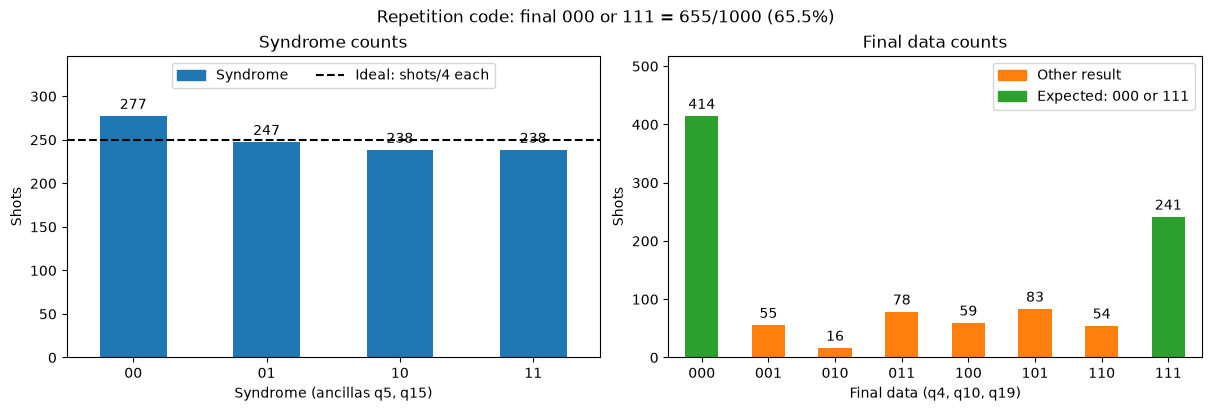

In [18]:
# Repetition-code syndrome and final-data distributions
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

results = repetition_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect repetition_job['raw_logs'].")

syndrome_labels = ["00", "01", "10", "11"]
data_labels = [f"{value:03b}" for value in range(8)]
expected_data = ("000", "111")  # every syndrome is corrected to one of these
syndrome_counts = pd.Series(
    {label: results["syndrome_counts"].get(label, 0) for label in syndrome_labels}
)
data_result_counts = pd.Series(
    {label: results["data_result_counts"].get(label, 0) for label in data_labels}
)
codeword_count = int(data_result_counts[list(expected_data)].sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
fig.suptitle(
    f"Repetition code: final 000 or 111 = {codeword_count}/{results['shots']} "
    f"({codeword_count / results['shots']:.1%})"
)
data_colors = ["tab:green" if label in expected_data else "tab:orange" for label in data_labels]
syndrome_counts.plot.bar(ax=axes[0], color="tab:blue", rot=0)
axes[0].axhline(results["shots"] / len(syndrome_labels), color="black", linestyle="--")
data_result_counts.plot.bar(ax=axes[1], color=data_colors, rot=0)
axes[0].set(title="Syndrome counts", xlabel="Syndrome (ancillas q5, q15)", ylabel="Shots")
axes[1].set(title="Final data counts", xlabel="Final data (q4, q10, q19)", ylabel="Shots")
axes[0].legend(handles=[
    Patch(color="tab:blue", label="Syndrome"),
    Line2D([], [], color="black", linestyle="--", label="Ideal: shots/4 each"),
], loc="upper center", ncols=2)
axes[1].legend(handles=[
    Patch(color="tab:orange", label="Other result"),
    Patch(color="tab:green", label="Expected: 000 or 111"),
])
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.25)
plt.show()

**How to read the repetition-code bar plots**

- **Left — syndrome:** Each bar counts the two-bit parity result from the first ancilla at **q5**, followed by the second ancilla at **q15**. With every data qubit starting in $|+\rangle$, all four syndromes are equally likely; the dashed line marks the ideal shots/4 per syndrome.
- **Right — final data:** Each three-bit label is the final measurement of the data qubits at **q4, q10, q19**, in that order. After feedback correction, only `000` and `111` (green) are expected, about half the shots each. The title gives their combined observed fraction.

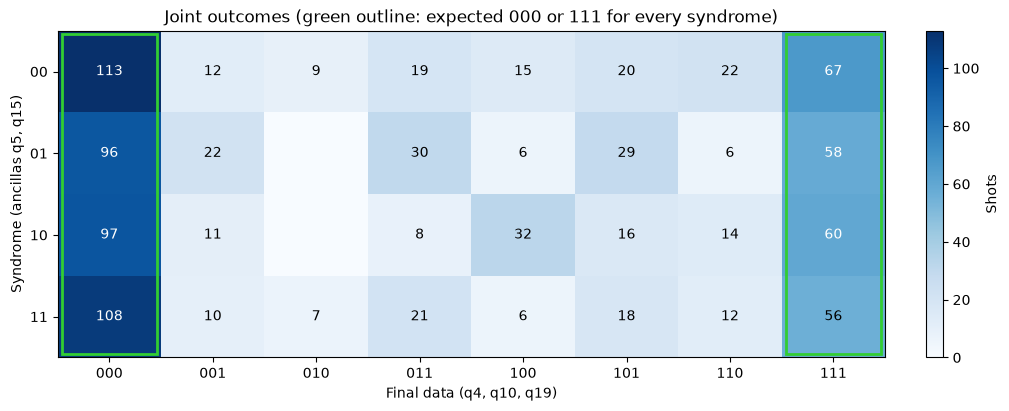

In [19]:
# Repetition-code joint outcomes: syndrome versus final data
from matplotlib.patches import Rectangle

results = repetition_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect repetition_job['raw_logs'].")

syndrome_labels = ["00", "01", "10", "11"]
data_labels = [f"{value:03b}" for value in range(8)]
joint_matrix = pd.DataFrame(0, index=syndrome_labels, columns=data_labels)
for outcome, count in results["joint_counts"].items():
    syndrome, data_result = outcome.split("->")
    joint_matrix.loc[syndrome, data_result] += count

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
image = ax.imshow(joint_matrix.to_numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(data_labels)), data_labels)
ax.set_yticks(range(len(syndrome_labels)), syndrome_labels)
ax.set(
    title="Joint outcomes (green outline: expected 000 or 111 for every syndrome)",
    xlabel="Final data (q4, q10, q19)",
    ylabel="Syndrome (ancillas q5, q15)",
)
fig.colorbar(image, ax=ax, label="Shots")
for data_result in ("000", "111"):
    column = data_labels.index(data_result)
    ax.add_patch(Rectangle(  # inset slightly so the outline is not hidden by the axes edge
        (column - 0.46, -0.46), 0.92, len(syndrome_labels) - 0.08,
        fill=False, edgecolor="limegreen", linewidth=2,
    ))
peak_count = joint_matrix.to_numpy().max()
for row, syndrome in enumerate(syndrome_labels):
    for column, data_result in enumerate(data_labels):
        count = joint_matrix.loc[syndrome, data_result]
        if count:
            ax.text(
                column, row, str(count), ha="center", va="center",
                color="white" if count > peak_count / 2 else "black",
            )
plt.show()

**How to read the repetition-code heatmap**

Each square combines a syndrome (row: first ancilla at q5, second at q15) with a final data result (column: q4, q10, q19). Darker blue means more shots. The green outlines mark the `000` and `111` columns: whichever syndrome was measured, the correction should leave the data in one of these two. Counts outside those columns show departures from ideal correction; the plot alone cannot identify their cause.